In [1]:
import io
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from datasets import load_dataset, Audio as HFAudio

<python>\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ds = load_dataset("atikuwu/karakalpak-speech-corpus", cache_dir="../hf_cache")
ds = ds.cast_column("audio", HFAudio(decode=False))
ds

DatasetDict({
    train: Dataset({
        features: ['id', 'audio', 'text', 'raw_text'],
        num_rows: 19554
    })
    validation: Dataset({
        features: ['id', 'audio', 'text', 'raw_text'],
        num_rows: 1074
    })
    test: Dataset({
        features: ['id', 'audio', 'text', 'raw_text'],
        num_rows: 1074
    })
})

In [3]:
sample = ds["train"][0]
print("text    :", sample["text"])
print("raw_text:", sample["raw_text"])
print("fayl    :", sample["audio"]["path"])

text    : Isbilermenlik subektleri ushın xabardar etiw tártibi engizilip, artıqsha ruqsat alıw processleri qısqartıldı. Juwmaqlap aytqanda, qáwipsizlikke tek ǵana jazalaw arqalı emes, al profilaktika arqalı erisiw áhmiyetli principlerden biri bolıp esaplanadı.
raw_text: Isbilermenlik subektleri ushın xabardar etiw tártibi engizilip, artıqsha ruqsat alıw processleri qısqartıldı. Juwmaqlap aytqanda, qáwipsizlikke tek ǵana jazalaw arqalı emes, al profilaktika arqalı erisiw áhmiyetli principlerden biri bolıp esaplanadı.
fayl    : 1906.ogg


In [4]:
wav, sr = sf.read(io.BytesIO(sample["audio"]["bytes"]), dtype="float32")
print("sampling rate: ", sr)
print("shakl        : ", wav.shape)
print("davomiylik   : ", round(len(wav) / sr, 2), "s")

sampling rate:  48000
shakl        :  (701448,)
davomiylik   :  14.61 s


In [5]:
display(Audio(wav, rate=sr))

[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


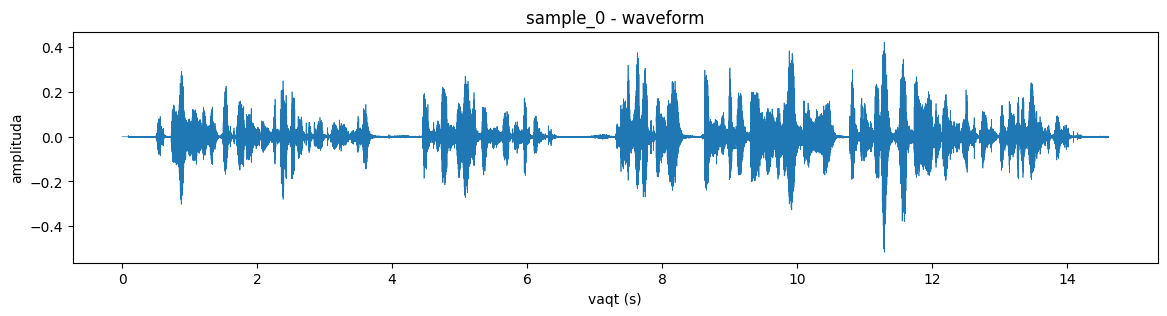

In [6]:
t = np.arange(len(wav)) / sr

plt.figure(figsize=(14, 3))
plt.plot(t, wav, linewidth=0.5)
plt.xlabel("vaqt (s)")
plt.ylabel("amplituda")
plt.title("sample_0 - waveform")
plt.show()

In [7]:
wav16 = librosa.resample(wav, orig_sr=sr, target_sr=16000)
wav8 = librosa.resample(wav, orig_sr=sr, target_sr=8000)

for name, w, r in [("48k", wav, sr), ("16k", wav16, 16000), ("8k", wav8, 8000)]:
    print(f"{name}: {len(w):>7} namuna, {len(w) / r:.2f} s")

48k:  701448 namuna, 14.61 s
16k:  233816 namuna, 14.61 s
8k:  116908 namuna, 14.61 s


In [8]:
print("16 kHz:"); display(Audio(wav16, rate=16000))
print("8 kHz:"); display(Audio(wav8, rate=8000))

# XATO: 48 kHz audioni 16 kHz deb o'ynatsak, sekin va past eshitiladi
print("XATO:"); display(Audio(wav, rate=16000))

16 kHz:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


8 kHz:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


XATO:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


In [9]:
import pandas as pd
from tqdm.auto import tqdm

def get_info(example, split):
    info = sf.info(io.BytesIO(example["audio"]["bytes"]))
    return {
        "split"     : split,
        "id"        : example["id"],
        "sr"        : info.samplerate,
        "channels"  : info.channels,
        "duration": info.duration,
        "n_chars"   : len(example["text"]),
        "n_words"   : len(example["text"].split()),
        "text"      : example["text"],
    }

get_info(ds["train"][0], "train")

{'split': 'train',
 'id': 0,
 'sr': 48000,
 'channels': 1,
 'duration': 14.6135,
 'n_chars': 250,
 'n_words': 29,
 'text': 'Isbilermenlik subektleri ushın xabardar etiw tártibi engizilip, artıqsha ruqsat alıw processleri qısqartıldı. Juwmaqlap aytqanda, qáwipsizlikke tek ǵana jazalaw arqalı emes, al profilaktika arqalı erisiw áhmiyetli principlerden biri bolıp esaplanadı.'}

In [10]:
rows = []

for split in ["train", "validation", "test"]:
    for example in tqdm(ds[split], desc=split):
        rows.append(get_info(example, split))

df = pd.DataFrame(rows)

print("Jami qatorlar: ", len(df))
df.head()

test: 100%|██████████| 1074/1074 [00:03<00:00, 303.99it/s]


Jami qatorlar:  21702


,split,id,sr,channels,duration,n_chars,n_words,text
0,train,0,48000,1,14.6135,250,29,Isbilermenlik subektleri ushın xabardar etiw t...
1,train,1,48000,1,15.4400,232,29,Bul jol arqalı Shımbay tek ǵana ishki ekonomik...
2,train,2,48000,1,17.7735,280,35,Tutınıw sebetindegi ónim hám xızmetlerdiń jetp...
3,train,3,48000,1,20.2735,301,38,Jergilikli qatnasıwshılar ushın kórgizbeniń ek...
4,train,4,48000,1,14.7735,284,31,"Sessiyanıń kún tártibindegi dáslepki másele ""Q..."


In [11]:
summary = df.groupby("split")["duration"].agg(
    count = "count",
    hours = lambda d: d.sum() / 3600,
    min_s = "min",
    mean_s = "mean",
    median_s = "median",
    max_s = "max",
).round(2)

print("Jami soat: ", round(df["duration"].sum() /3600, 2))
summary

Jami soat:  106.92


,count,hours,min_s,mean_s,median_s,max_s
split,,,,,,
test,1074,5.24,6.49,17.58,17.22,35.49
train,19554,96.40,6.41,17.75,17.09,40.25
validation,1074,5.27,6.75,17.68,16.88,35.33


In [12]:
print("Sampling rate lar:")
print(df['sr'].value_counts())

print("\nKanallar soni:")
print(df["channels"].value_counts())

Sampling rate lar:
sr
48000    21702
Name: count, dtype: int64

Kanallar soni:
channels
1    21702
Name: count, dtype: int64


In [23]:
SPLITS = ["train", "validation", "test"]

all_raw  = [t for s in SPLITS for t in ds[s]["raw_text"]]
all_text = [t for s in SPLITS for t in ds[s]["text"]]

# Tekshiruv:
assert df["text"].tolist() == all_text, "Tartib mos emas!"

df["raw_text"] = all_raw
df["idx"] = df.groupby("split"). cumcount()
print("OK", df.shape)

OK (21702, 11)


In [24]:
# MISSING VALUE

print("NAN soni ustunlarda:")
print(df.isna().sum())

empty_text = df["text"].fillna("").str.strip().eq("")
empty_raw  = df["raw_text"].fillna("").str.strip().eq("")
print("\nBo'sh text     :", empty_text.sum())
print("Bo'sh raw_text :", empty_raw.sum())

# Mantiqan "yetishmayotgan" ma'lumot: 6+ soniyali audioga 1-2 so'z to'g'ri kelmaydi
print("3 so'zdan kam matn :", (df["n_words"] < 3).sum())
print("1 s dan qisqa audio:", (df["duration"] < 1).sum())

NAN soni ustunlarda:
split       0
id          0
sr          0
channels    0
duration    0
n_chars     0
n_words     0
text        0
raw_text    0
idx         0
cps         0
dtype: int64

Bo'sh text     : 0
Bo'sh raw_text : 0
3 so'zdan kam matn : 0
1 s dan qisqa audio: 0


In [25]:
# ID unique

print(df.groupby("split")["id"].agg(["min", "max", "nunique", "count"]))
print("\n(split, id) juftligi takrorlari:", df.duplicated(["split", "id"]).sum())

            min    max  nunique  count
split                                 
test          0   1073     1074   1074
train         0  19553    19554  19554
validation    0   1073     1074   1074

(split, id) juftligi takrorlari: 0


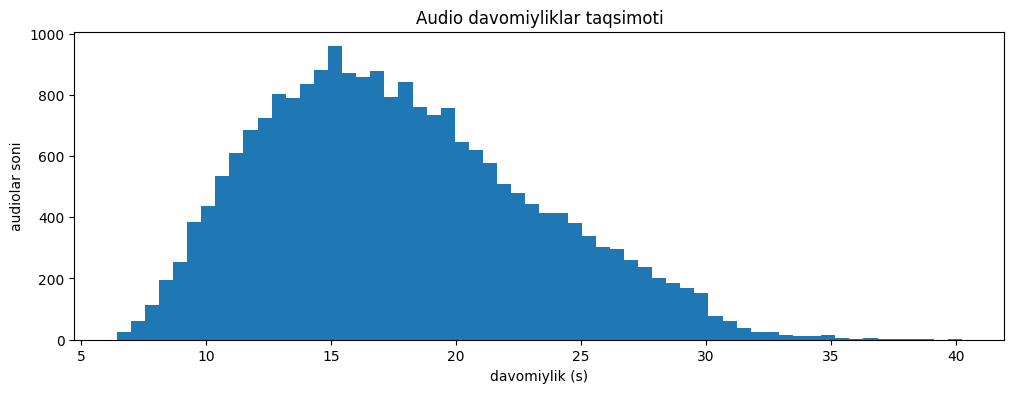

In [26]:
plt.figure(figsize=(12, 4))
plt.hist(df["duration"], bins=60)
plt.xlabel("davomiylik (s)")
plt.ylabel("audiolar soni")
plt.title("Audio davomiyliklar taqsimoti")
plt.show()

In [27]:
df["cps"] = df["n_chars"] / df["duration"]

print(df["cps"].describe().round(2))

# Chegara: o'rtacha qiymatdan 3 std pastda va yuqorida
cps_mean = df["cps"].mean()
cps_std = df["cps"].std()
past_chegara = cps_mean - 3 * cps_std
yuqori_chegara = cps_mean + 3 * cps_std
print("\nChegaralar:", round(past_chegara, 2), "___", round(yuqori_chegara, 2))

suspicious = df[(df["cps"] < past_chegara) | (df["cps"] > yuqori_chegara)]
print("Shubhali qatorlar: ", len(suspicious))

count    21702.00
mean        16.00
std          2.87
min          5.47
25%         14.10
50%         15.78
75%         17.78
max         24.98
Name: cps, dtype: float64

Chegaralar: 7.4 ___ 24.6
Shubhali qatorlar:  48


In [28]:
def listen(split, idx):
    ex = ds[split][idx]
    wav, sr = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    print(f"[{split} #{idx}] {len(wav)/sr:.1f} s")
    print(ex["text"])
    display(Audio(wav, rate=sr))

In [29]:
s = suspicious.sort_values("cps")

# Eng SEKIN 3 tasi (jadval boshi)
for _, row in s.head(3).iterrows():    # iterrows() — jadval qatorlarini birma-bir beradi
    listen(row["split"], row["idx"])

# Eng TEZ 3 tasi (jadval oxiri)
for _, row in s.tail(3).iterrows():
    listen(row["split"], row["idx"])

[train #8811] 29.1 s
Bul jumıslar sırt el aukcionları, ilimiy mákemeler, jeke menshik kollekciyalar hám xalqımız tárepinen keltirilgen derekler esabınan turaqlı dawam ettirilmekte.


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


[train #15327] 25.8 s
Sonday-aq, zárúr jaǵdaylarda qıstawlı baylanıs hám operativ múrájat etiw ushın elshixananıń baylanıs quralları kúni-túni jedel isleytuǵını málim etildi. F. Yaxshiboeva, ÓzA


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


[train #7655] 27.0 s
Ilaj Túrkmenstan Májilisi tárepinen BMShtıń Xalıqtanıw qorı UNFPA menen birgelikte xalıqaralıq shólkemler hám segiz mámleket parlamentleriniń wákilleriniń qatnasıwında shólkemlestirildi.


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


... (2 outputs left out)

[validation #622] 13.7 s
Ózbekstan Respublikası Ministrler Kabinetiniń eki mıń on besinshi jıl jigirma toǵız-avgustta "Aral apatshılıǵınıń aqıbetlerin jumsartıw, Aralboyı aymaǵın eki mıń on bes-eki mıń on segizinshi-jıllarda sociallıq-ekonomikalıq jaqtan rawajlandırıw hám qayta tiklew boyınsha ilajlardıń kompleksli baǵdarlaması haqqında"ǵı qararı qabıl etilgen edi.


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


[train #9736] 13.7 s
Usı múnásibet penen eki mıń jigirma altınshı jılı úsh pútin onnan bes million sırt el hám bes pútin onnan bes million jergilikli turistti tartıw, ulıwma turistler sanın toǵız millionǵa jetkeriw wazıypası qoyıldı. Bunıń ushın eki mıń jigirma altınshı jılı jetpis úsh jańa jaylastırıw quralı, on bes jańa turoperator hám turagent iske qosıladı.


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


In [30]:
# Shart bo'yicha filtrlab, har bir split'da nechtadan borligini sanaymiz
long = df[df["duration"] > 30]
print("30 s dan uzun:", len(long), "ta,", round(long["duration"].sum() / 3600, 2), "soat")
print(long["split"].value_counts())

30 s dan uzun: 328 ta, 2.91 soat
split
train         299
test           15
validation     14
Name: count, dtype: int64


In [31]:
df.to_csv("Dataset_tahlil.csv", index=False, encoding="utf-8-sig")
summary.to_csv("dataset_summary.csv", encoding="utf-8-sig")

print("Saqlandi")

Saqlandi
